# Offline training and environment improvements

> #### AI usage disclaimer
> I used an AI agent to help make these code changes and to review this notebook.  
> I did not verify all of the code produced by the AI thoroughly, big chunks are verified just functionally.  
> I provide an executive summary of the changes here, however all of the changes were my vision or inspired from other people's approaches, which were credited here.  
> I don't mention how every component is used, it would make this already large notebook even larger - this is done in the README.md  

## TD3 and behavior cloning

We've been training with **PPO**. I've added **TD3** as a second algorithm which also works with **behavior cloning (BC)**.
SB3 also provides it, so it's essentially the same code, just replacing `PPO` with `TD3`, at a basic level. 

### Why add a second algorithm

**PPO** is **on-policy**: it learns from the most recent batch of episodes and then
throws that experience away. Every step of the (slow) game is therefore used
just once.

**TD3** is **off-policy**: it keeps a **replay buffer** of past experiences and
samples random batches from it to learn, so one experience can be reused many
times.

So **TD3** was chosen for its perceived efficiency gain in training time.

### What TD3 actually is

[TD3](https://spinningup.openai.com/en/latest/algorithms/td3.html#background) = **Twin Delayed Deep Deterministic Policy Gradient (DDPG)**.

In plain terms it's an **actor-critic** method: it learns two networks at once.

- **Actor** = the policy - the network that turns the observation into an action. In TD3 it's a deterministic one: the same situation always gives the same action, no distribution.
- **Critic** = a Q-function - a network that scores actions.

#### What a Q-function is

A Q-function takes a situation and an action and returns a single number: the expected total reward `r` from this moment, if you take action `a` now and then keep playing well.

That Q-function results in a Q-value - a value representing how much reward can be expected by taking an action. Once you have a Q-function, the policy is almost trivial - in any situation, just take the action with the highest Q-value.

#### How the Q-function learns

There are no human labels for Q - no one is telling it the right number - so it learns from the game itself, by correcting its own estimate of the next step. The equation is:

    Q(s, a) ~= r + Q(s', a')

where `r` is the reward the step just gave, `s'` is the situation you ended up in, and `a'` is the action the policy would take there.

Concretely: you're mid-drift, the step just paid `+0.5` of reward, and your current estimate says the situation you landed in is worth `1` more reward if the policy keeps driving. So the training target for the (situation, action) you just had is `0.5 + 1 = 1.5`, and the critic is nudged so that `Q(s, a)` gets closer to `1.5`. Every step produces one such correction, and the estimate sharpens over time.

The catch is that the equation is circular: the target is built from Q itself. Left alone, the estimate chases its own tail - and the way it fails is *overestimation*: the critic finds situations where its own number is too high, the policy gets sent there, and the high number gets reinforced. 

The name TD3 is essentially a list of fixes for DDPG problems (quoted fixes from the OpenAI page):

> **Trick One**: *Clipped Double-Q Learning*. TD3 learns two Q-functions instead of one (hence “twin”), and uses the smaller of the two Q-values to form the targets in the Bellman error loss functions.
>
> **Trick Two**: *“Delayed” Policy Updates*. TD3 updates the policy (and target networks) less frequently than the Q-function. The paper recommends one policy update for every two Q-function updates.
>
> **Trick Three**: *Target Policy Smoothing*. TD3 adds noise to the target action, to make it harder for the policy to exploit Q-function errors by smoothing out Q along changes in action.

The **replay buffer** (the off-policy part from the first section) is where all of this gets its data: the `(s, a, r, s')` transitions are stored as they happen and sampled in random batches for the updates, so one observation from the slow environment can be used for corrections many times.

In the implementation, two CLI flags are directly related to the above tricks:

- `--train-freq N` — one gradient step every `N` env steps. SB3's default is *one update per episode*, far too rare for a 15-60s episode; we default to one update per 4 steps, which obviously cuts into the delay trick, but it seemingly works well.
- `--action-noise σ` — TD3 is deterministic and has no built-in exploration, so this adds Gaussian noise to the actions it *takes* (not to what it *learns*). It's how TD3 explores.

### Kinds of policies

We already covered that a **policy** is the neural network that turns an observation into an action.
There are two flavors, and this difference was also worth testing in practice.

- **Stochastic (PPO).**  
For a given situation it outputs a *range* of possible actions with probabilities — a **Gaussian** with a center (best guess) and a spread (how unsure it is) - it is a fancy word that can be portrayed by a bell curve, which I'm sure you've seen before.  
Because it's a distribution, when training we must optimize "how *likely* was the human's action?".
- **Deterministic (TD3).**  
For a given situation it outputs *one* action; the same input always gives the same output. There is no distribution, so "how likely" is not an applicable concept for this policy type. A specific observation always results in the corresponding specific action.
This means if your observation is the exact same between steps, and your agent in that situation chooses to brake, then it's stuck.
Since there's only a specific action linked to an observation, the training objective is to match the action given the observation - and in BeamNG.tech even with our simplified observation space there are many possible observation space variations.

In [7]:
# The two policy types and the two cloning objectives they imply.
import numpy as np
import torch as th
import torch.nn.functional as F
import gymnasium as gym
from gymnasium import spaces
from stable_baselines3 import PPO, TD3
from stable_baselines3.ppo import MultiInputPolicy as PpoPol
from stable_baselines3.td3 import MultiInputPolicy as Td3Pol

obs = spaces.Dict({
    "bev": spaces.Box(0, 1, (64, 64), dtype=np.float32),
    "rpm": spaces.Box(0, 1, (1,), dtype=np.float32),
    "gear": spaces.Box(0, 1, (1,), dtype=np.float32),
})
act = spaces.Box(-1, 1, (4,), dtype=np.float32)

class _Dummy(gym.Env):
    observation_space, action_space = obs, act
    def reset(self, seed=None, options=None):
        return self.observation_space.sample(), {}
    def step(self, a):
        return self.observation_space.sample(), 0.0, True, False, {}

def batched(bs):
    return {k: th.as_tensor(np.stack([obs.spaces[k].sample() for _ in range(bs)]),
                            dtype=th.float32) for k in obs.spaces}

o = batched(8)
a = th.as_tensor(np.stack([act.sample() for _ in range(8)]), dtype=th.float32)

ppo = PPO(PpoPol, _Dummy(), device="cpu").policy
td3 = TD3(Td3Pol, _Dummy(), device="cpu").policy

print("== policy type ==")
print(f"PPO  has get_distribution: {hasattr(ppo, 'get_distribution')}")
print(f"TD3  has get_distribution: {hasattr(td3, 'get_distribution')}")

print("\n== behavior cloning objective ==")
d = ppo.get_distribution(o)
print(f"PPO  NLL  = {-d.log_prob(a).mean().item():.4f}   (maximize log-likelihood)")
pred = td3.forward(o, deterministic=True)
print(f"TD3  MSE  = {F.mse_loss(pred, a).item():.4f}   (regress the action)")

== policy type ==
PPO  has get_distribution: True
TD3  has get_distribution: False

== behavior cloning objective ==
PPO  NLL  = 4.4955   (maximize log-likelihood)
TD3  MSE  = 0.3939   (regress the action)


### How behavior cloning differs for the policy types

In the output above you can see the policy type contrast between PPO and TD3, packaged as a programmatic check for a `get_distribution` function presence under a SB3 policy python object.

The `PPO` policy has the `get_distribution` function, which shows that it is a Stochastic type of policy. The `TD3` policy does not present this function, showing that it is a Deterministic type of policy.

Because the policies differ with regards to the kinds of outputs they can produce, behavior cloning works differently for these policies too.
To even begin to nudge the weights - the parameters of the model - in the right direction, we should first address a basic concept of reinforcement learning - the loss function.

The loss function is the method used in reinforcement learning to quantify just how far the predicted action's value is from the ideal action value, given an observation (a situation) and its context (the past observations). It's essentially a way to say how good an action was by quantifying how far from ideal it is, in its circumstance.

It's clearly useful when there is some data to compare the trajectory with, data which is known to be good - with a value pre-determined by a human or an algorithm - this data is commonly referred to as a validation dataset and it is usually deliberately kept separate from the dataset used for training, because knowing how far a trajectory is from the ideal means having an ideal in the first place, and in the machine learning space this is the validation dataset.

In the second part of the output above we print two different loss functions:
- **NLL** - Negative Log Likelihood
- **MSE** - Mean Squared Error


#### Mean Squared Error

This loss function is well explained in fastbook - [Stochastic-Gradient-Descent-(SGD)](https://github.com/fastai/fastbook/blob/master/04_mnist_basics.ipynb#Stochastic-Gradient-Descent-(SGD)) - look for the part where it walks the loss -> gradient -> step loop on a simple quadratic example, the same squared shape we're using here.

Essentially it's `mean((human - pred)²)` - say if the `human` given a certain observation (in a situation) would choose to steer `human = -0.8` (80% of the steering wheel travel to the left) and the model predicts `pred = 0.1` in this situation, `human - pred` would be `-0.8 - 0.1 = -0.9`, and if we square `-0.9` we make the direction irrelevant (`(-0.9)² = 0.81`) and at the same time the error is not uniform, but higher when the difference is higher and lower when the difference is small (for a `0.1` difference of `human - pred` would be `(0.1)² = 0.01`) - which translates to big policy adjustments when the difference is high and small policy adjustments when it's low.

Having a mean value is necessary because we're not working with just one observation nor just one action.

A deterministic policy like TD3 outputs a single value per action - no distribution, no spread - which is why MSE is good to measure the loss.

#### Negative Log Likelihood

To understand negative log likelihood we can first look at the explanation in fastbook of the [Cross Entropy Loss](https://github.com/fastai/fastbook/blob/master/05_pet_breeds.ipynb#Cross-Entropy-Loss) - cross-entropy is what NLL looks like when the model's output is one of a fixed list of categories, and our actions are continuous numbers, but the name and the idea carry over. In practice maximizing the likelihood is the same as minimizing the cross entropy.

Where the TD3 policy outputs a single point per action, the PPO policy outputs a bell curve (a Gaussian: a center `mean` and a width `sigma`) per action. The **likelihood** of the human's action is the density that bell curve puts on it - how plausible the human's action is, according to the model. **NLL** is just the negative log of that: `-log(density)`.

In the same situation as above - the `human` steers `human = -0.8`. A model whose bell curve is centered at `0.1` (with a width of `0.2`) puts almost no density out at `-0.8` - it's 4.5 widths away from the center, deep in the tail - so the density is about `0.00008`, its log is about `-9.4`, and the NLL is about `9.4`: the model says *I'd never steer that far*. A model whose bell curve is centered on `-0.8` puts the human's action right on the peak: the density is about `2.0`, its log about `0.7`, and the NLL about `-0.7`: the model says *that's exactly what I'd do*. Minimizing the NLL therefore drags the peak of the curve onto the human's action - the same thing MSE does, but on a curve instead of a point.

The two terms in the name which sit next to **likelihood** essentially mean:
- **log**: a training batch has hundreds of (situation, human action) pairs, and combining their likelihoods means multiplying hundreds of tiny probabilities, which underflows; `log` turns that product into a sum, so `mean(log_prob)` is the *average evidence* that the model would do what the human did.
- **negative**: gradient descent only knows how to *minimize*, and we want to *maximize* the chance the model picks the human's action - the minus sign flips it. Minimizing NLL = maximizing the likelihood of the human's action.

This is exactly the loss printed above (`-d.log_prob(a).mean()`), and in `train_bc` there is an optional second term, `entropy_coef * entropy`, which pays the model a bonus for keeping the bell curve a little wide, so it doesn't collapse onto a single point and stop exploring (it's `0` by default).

And the two sections connect: if you fix the width of the bell curve, the NLL of a Gaussian is just `½·((x - mean)² / sigma²)` plus a constant - a scaled MSE. MSE is what NLL reduces to when the model can't change its spread. The goal is the same - imitate the human (data) - expressed in the language each policy understands.


### The implementation

A few changes were needed across the training package:

**1. A registry maps the algorithm name to its SB3 classes** (`common.py`)  
Both policies take the same `(policy, env, ...)` constructor, so the rest of the code is written once and driven by this table:

```python
ALGOS = {
    "ppo": (PPO, PpoPolicy),
    "td3": (TD3, Td3Policy),
}
```

**2. `train_bc` picks the objective from the policy type** (`commands/offline.py`)  
It checks whether the policy has the `get_distribution` function:

```python
stochastic = hasattr(policy, "get_distribution")
...
if stochastic:
    dist = policy.get_distribution(obs)
    log_prob = dist.log_prob(actions)
    entropy = dist.entropy()
    loss = -log_prob.mean() - args.entropy_coef * entropy.mean()
    pred = dist.mode()
else:
    pred = policy.forward(obs, deterministic=True)
    loss = th.nn.functional.mse_loss(pred, actions)
```

This is the basic implementation of behavior cloning, for both policy types:

**Stochastic**
- `dist = policy.get_distribution(obs)` is a bell curve (range of possible actions with probabilities) based on the situation (observation)
- `log_prob = dist.log_prob(actions)` is the log likelihood of the human's actions compared to that bell curve `dist`
- `loss = -log_prob.mean() - args.entropy_coef * entropy.mean()` is the NLL (negative log likelihood), but also with an entropy coefficient
- `pred = dist.mode()` is just the peak of the bell curve (the most likely action set) for printing RMSE, it isn't used in the behavior cloning approach taken here.

**Deterministic**
- `pred = policy.forward(obs, deterministic=True)` represents a single action set the policy makes based on the observation
- `loss = th.nn.functional.mse_loss(pred, actions)` is the mean squared error (MSE) loss when comparing the prediction to the human's actions

After either branch produces a `loss`, the same three lines run no matter the algorithm:

```python
  optimizer.zero_grad()
  loss.backward()
  optimizer.step()
```

These three lines represent gradient descent, which is how weights are adjusted in the direction which would produce a smaller loss, explained at length in fastbook chapter 4 - [Stochastic-Gradient-Descent-(SGD)](https://github.com/fastai/fastbook/blob/master/04_mnist_basics.ipynb#Stochastic-Gradient-Descent-(SGD)).

`def apply_step(params, prn=True):` in that fastbook chapter 4 performs the same thing.

Here are the explanations from that book applied to our implementation context which uses SB3:

**`loss.backward()`**:
> As we will see, the magic of calculus allows us to directly figure out in which direction, and by roughly how much, to change each weight, without having to try all these small changes. The way to do this is by calculating *gradients*. This is just a performance optimization, we would get exactly the same results by using the slower manual process as well.

>The "backward" here refers to backpropagation, which is the name given to the process of calculating the derivative of each layer. [..]. This is called the "backward pass" of the network, as opposed to the "forward pass," which is where the activations are calculated. Life would probably be easier if backward was just called calculate_grad, but deep learning folks really do like to add jargon everywhere they can!

Fastbook also explains the backwards pass in excruciating detail in the [Foundations](https://github.com/fastai/fastbook/blob/master/17_foundations.ipynb#Gradients-and-the-Backward-Pass) chapter, which is also where every implementation detail of a basic neural network is explained. 

**`optimizer.zero_grad()`**:  
> `loss.backward` actually *adds* the gradients of `loss` to any gradients that are currently stored. So, we have to set the current gradients to 0 first

**`optimizer.step()`**  
This is the equivalent of the fastbook `apply_step` function line `params.data -= lr * params.grad.data`, it is the actual step that uses the direction in which the weights should be adjusted and actually makes the adjustment based on the configured learning rate `lr`.

The `optimizer` object represents a PyTorch optimizer — specifically `torch.optim.Adam`, built at the top of `train_bc`.

**3. The online model gets algorithm-specific constructor kwargs** (`commands/online.py`)  
PPO takes an entropy bonus; TD3 takes `train_freq` and `action_noise` (and has no `ent_coef` at all):

```python
kwargs = dict(verbose=1, tensorboard_log=log_dir)
if args.algo == "ppo":
    kwargs["ent_coef"] = args.ent_coef
else:
    kwargs["train_freq"] = (args.train_freq, "step")
    if args.action_noise > 0:
        kwargs["action_noise"] = NormalActionNoise(
            mean=np.zeros(dim), sigma=np.full(dim, args.action_noise))
```

**4. Loaded models get their noise rebuilt from the CLI argument** (`commands/online.py`)  
A model loaded from a zip inherits its hyperparameters from the zip, and the saved `action_noise` is a `VectorizedActionNoise` tied to the env count at save time.  
Resuming a 2-endpoint checkpoint with 1 endpoint is problematic in this case - the `(2, 8)` noise no longer fits the `(1, 8)` action.  
BC trained models have no noise at all, so a loaded TD3 would otherwise run fully deterministic. 

After loading, `cmd_online` therefore rebuilds `action_noise` for every TD3 model:

```python
if args.algo == "td3":
    from stable_baselines3.common.noise import NormalActionNoise
    dim = _action_dim(env)
    model.action_noise = (
        NormalActionNoise(mean=np.zeros(dim),
                          sigma=np.full(dim, args.action_noise))
        if args.action_noise > 0 else None)
```

## Human mode

This change lets me drive the car and collects data until interrupted.

In human mode the env sends no `Control` - the game's own input (wheel, pedals, or keyboard) drives the car.  
The game runs freely at real time (not paused, not stepped), because I discovered a paused car has no force feedback, I needed that to actually drift well. This also made me realize I should have made force feedback part of the observation space - more on that later.

Each step the env reads the applied action back from the electrics sensor and returns it as `info["applied_action"]`. The steering wheel angle is normalised by the car's steering wheel lock into the `[-1, 1]` steering axis, throttle and brake are read from the `*_input` fields (the driver's actual pedal input), and the gear axis encodes the gear the driver selected via `gear_to_action` (the closest allowed gear, matching the action the env would have sent).
  
The window is larger in this mode (`1280x720`) so the UI doesn't overlay on top of the car to the extent it does at the lower resolution.

In [1]:
import numpy as np
import gymnasium as gym
import beamng_tech_env  # registers the env id

# human_mode=True: a person drives, the env records the applied action
env = gym.make("beamng_tech_env/BeamNGTech-v0.39", human_mode=True)
obs, info = env.reset()
# step with a dummy action; the real action comes back in info["applied_action"]
obs, reward, terminated, truncated, info = env.step(np.zeros(8, dtype=np.float32))
print("applied action:", info["applied_action"])

[    0.30s] reset requested; prev_damage: 0.0; prev_timer: 0; lowpressure: 0.0
[    0.30s] setup: connecting to game at localhost:25252


[    8.02s] setup: connected, loading scenario
[   64.52s] setup: scenario loaded
[   64.69s] setup: 838 waypoints
[   72.51s] setup: scenario started
[   74.03s] setup: done (paused)
[   74.03s] reset: first_time_setup done
[   74.57s] reset: resumed
[   74.81s] reset: scenario restarted
[   76.01s] setup: vehicle added {'model': 'etki', 'part_config': 'drift'} at waypoint tunnel_city_C_14 (18.7, 256.0, 97.4)
[   76.06s] reset: sensors set up
[   76.06s] reset: running free (human mode), polling sensors
[   76.16s] reset: human mode ready (steering wheel lock=450 deg, physics at real time)
[   77.81s] reset: done
applied action: [0. 0. 0. 0. 0. 0. 0. 0.]


In the data collection mode you're placed in the same environment conditions as the AI is placed - you have to drive for up to 60 seconds and each crash means the episode is terminated or staying still means the episode is truncated.

```bash
python -m data.collect --out data
```

Being able to drive in this same environment I set up for training / reinforcement learning highlighted all of the bad choices made, so I began to correct them - examples are missing the steering wheel force feedback from the observation space or how the automatic gearbox affects drifting. These are addressed in the following sections with added context.

## A fixed car

The env used to pick a random drift car from `DRIFT_CARS_6SPEED` on every reset. That made runs hard to compare: the same policy would face a different car, with changed weight, steering geometry, etc.
I discovered the hard way that generalization (applying learned policies to slightly varying environments) is the hardest task in the AI space.

This generalization problem is still likely to stay a problem because I'm frequently changing the spawn location or heading, but I'm not willing to give up the ambition of making the drifting agent drive anywhere (with at least a decent level of quality at this point).

The fix for the vehicle generalization issue is to pin the car. The env now always spawns `FIXED_CAR`:

In [1]:
# The env now always spawns this car (previously a random draw from DRIFT_CARS_6SPEED)
FIXED_CAR = {"model": "etki", "part_config": "drift"}
print(FIXED_CAR)

{'model': 'etki', 'part_config': 'drift'}


The benchmark can still override the car per reset with `options={"car": ...}`, so you can test other cars without changing the default. But for training and data collection the car is fixed, which means every episode and every run is comparable.

## Gearbox actions

In arcade mode the car has no gear control - throttle / brake controls were resulting in gear changes indirectly. 
That's easy to drive but it throws away a big part of driving a manual car, plus the BeamNG automatic gearbox isn't really suited for drifting - I tried drifting with it and it either switches away from gears I need or doesn't switch to gears I need quite frequently.    
This iteration updates the env to a realistic manual gearbox and gives the agent a gear to shift.

The gearbox is set to `realistic_manual`. The clutch is left to the game's autoClutch assist, so the agent doesn't need a separate clutch input - it just picks gears and the clutch is handled.

The action space for this was initially updated to have a fourth action for the gear. It was an *absolute* gear selection, but I also attempted a sequential shift action. The axis was a continuous value in `[-1, 1]` mapped to an index into `ALLOWED_GEARS` (see `action_to_gear` / `gear_to_action`). Neutral, 5th and 6th were later removed from the action space, so the agent picked from reverse and 1st-4th. 

I noticed the policy would be refined to encourage the max of this axis when shifting forward was identified to be beneficial, which resulted in the max gear being selected later in training (6th and later 4th with the limited gear range). 

This is how the latest failed attempt had worked (or failed, in the sense that it was hard to learn):


In [1]:
import numpy as np
import gymnasium as gym

# the action is now 4-dim: [steering, throttle/brake, parkingbrake, gear]
action_space = gym.spaces.Box(
    low=np.array([-1.0, -1.0, -1.0, -1.0]),
    high=np.array([1.0,  1.0,  1.0,  1.0]),
    dtype=np.float32,
)
print("action shape:", action_space.shape)

# absolute gear: the gear axis is a continuous value in [-1, 1] mapped to an
# index into ALLOWED_GEARS (neutral, 5th and 6th removed from the action space)
ALLOWED_GEARS = [-1, 1, 2, 3, 4]
def resolve_gear(gear_cmd):
    n = len(ALLOWED_GEARS)
    idx = int(np.clip(round((gear_cmd + 1.0) / 2.0 * (n - 1)), 0, n - 1))
    return ALLOWED_GEARS[idx]

for cmd in [-1.0, -0.5, 0.0, 0.5, 1.0]:
    print(f"cmd={cmd:+.3f} -> gear {resolve_gear(cmd):+d}")


action shape: (4,)
cmd=-1.000 -> gear -1
cmd=-0.500 -> gear +1
cmd=+0.000 -> gear +2
cmd=+0.500 -> gear +3
cmd=+1.000 -> gear +4


The gear is also an observation, normalised to `[0, 1]` so the policy can see which gear it's in: `(gear + 1) / (MAX_GEAR + 1)`.

To counter the gear action maximization problem, I took inspiration from how LLMs organize their action space - they have tokens (which are parts of words or even symbols, with no implied intrinsic meaning) that the agent can choose as an action to complete the context history (or trajectory) - simply explained the words up until the action is requested (completing the words context). Each token is an individual action in the action space of an LLM and this is commonly named `vocabulary`.

Inspired by this, I decided to experiment with the same approach for gear selection - to have a range of gears mapped as individual actions instead. I chose to have gears `[-1, 1, 2, 3, 4]` as actions - my `vocabulary` for the gearbox.

In practice, the gear actually reaching as an action in the game was the max between all gear actions the policy has in it's gearbox `vocabulary`. This significantly helped the policy with gear selection.

## Steering force feedback

Force feedback (FFB) is the torque the steering wheel applies back to the driver's steering wheel. 
I had to actually place myself in the environment to realize I missed this really important part of the observation space.

It's a strong signal about what the car is doing - a heavy wheel means the front is loaded, a light wheel means it's turning freely and of course the car's steering geometry results in self-centering or other forces. Exposing it as an observation should obviously help with drifting since for me it's the main signal.

The env reads it from the game's `hydros` lua module (`ego.queue_lua_command("return hydros.forceAtDriverNorm", response=True)`, already normalised to `[-1, 1]`). In agent mode the env enables the game's *virtual wheel* so the FFB is computed with no physical wheel hardware. In human mode a real wheel is assumed to be connected and drives the FFB, so the virtual wheel isn't added.

## BEV improvements

### SB3 NatureCNN compatibility

We still need to address the BEV observation issue from the previous notebook: the default `CombinedExtractor` flattens the BEV instead of running a CNN on it, so the model receives the map as one long vector with no spatial processing / information.

The simplest way to give the BEV a CNN is to make SB3 treat it as an image. `CombinedExtractor` makes this decision per key with the `is_image_space` function - if it returns `True` the key goes through a `NatureCNN`, otherwise it's flattened. That function is conservative: it returns `False` on any doubt. For a key to count as an image its space must be a `Box` with a **3-D** shape, and (unless `normalized_image` is set) `uint8` values in `[0, 255]`.

In [3]:
# is_image_space is what CombinedExtractor uses to decide, per key, between a
# CNN and a flatten. The old BEV fails it; the new one passes.
import numpy as np
import gymnasium as gym
from stable_baselines3.common.preprocessing import is_image_space

BEV_N = 64
old_bev = gym.spaces.Box(0.0, 1.0, (BEV_N, BEV_N), np.float32)   # before
new_bev = gym.spaces.Box(0, 255, (1, BEV_N, BEV_N), np.uint8)    # after

print("old  float32 (64, 64) [0, 1]     ->", is_image_space(old_bev))
print("new  uint8   (1, 64, 64) [0, 255] ->", is_image_space(new_bev))

old  float32 (64, 64) [0, 1]     -> False
new  uint8   (1, 64, 64) [0, 255] -> True


So I updated the BEV to be a `uint8` image: the `[0, 1]` float grid is scaled to `[0, 255]` and a leading channel dim is added, making it `(1, 64, 64)`. The road level (`0.5`) becomes `128`, the car footprint (`1.0`) becomes `255`. The conversion lives in the env (`_bev_to_obs`), and `lidar_bev` itself still returns the `[0, 1]` float grid - only the observation formatting changed. I also limited which LiDAR returns feed the grid: `lidar_bev` drops returns above `BEV_MAX_HEIGHT` (2 m), so tunnel and overpass ceilings no longer read as bright obstacles - only low returns (road, curbs, walls) and the painted car footprint reach the BEV.

In [14]:
# The conversion the env now applies: scale the [0, 1] float grid to [0, 255]
# uint8 and add a leading channel dim. Road (0.5) -> 128, car (1.0) -> 255.
import numpy as np

BEV_N = 64
grid = np.full((BEV_N, BEV_N), np.nan, np.float32)   # NaN = no LiDAR return
grid[30:34, 30:34] = 1.0                             # car footprint
grid[10:12, 40:45] = 0.9                             # an obstacle

def bev_to_obs(grid):
    grid = np.nan_to_num(grid, nan=0.5)
    return (np.clip(grid, 0.0, 1.0) * 255).round().astype(np.uint8)[None, ...]

obs = bev_to_obs(grid)
print("shape/dtype:", obs.shape, obs.dtype)
print("road (empty) =", obs[0, 60, 60], " car =", obs[0, 31, 31], " obstacle =", obs[0, 10, 40])

shape/dtype: (1, 64, 64) uint8
road (empty) = 128  car = 255  obstacle = 230


There's an alternative worth knowing about: the `normalized_image` parameter. When `CombinedExtractor` is built with `normalized_image=True`, `is_image_space` skips the dtype and bounds checks and only requires a 3-D `Box`. So the BEV could have stayed a `float32` grid in `[0, 1]`.

But it can't be used *without changing the BEV at all* - the 3-D shape requirement is always enforced, so the `(64, 64)` grid would still need the leading channel dim.  
The tradeoffs:

- **uint8 (chosen)**: no special policy kwargs, the standard image format, at the cost of float precision (256 levels is plenty for a height grid).
- **normalized_image**: keeps `float32` precision, but the policy needs `features_extractor_kwargs=dict(normalized_image=True)`.

### Observation improvements 

#### Filtered point cloud BEV

The BEV is also improved with LiDAR points identified as road surface removed at the point cloud stage. This is done with information about the road network that comes directly from the game. 

##### Applicability beyond the simulation

In reality this is achievable with models trained on datasets such as: [nuScenes](https://www.nuscenes.org/) - because the nuScenes dataset contains, among other data, LiDAR points which are annotated with classes. 

The removal of the drivable road surface points lets the obstacles on the road avoid blending with lidar points caused by sloped roads or the vehicle banking while driven to the limit. We don't classify further than obstacle or non-obstacle in our exploration, at this point.

Another way to translate this in reality is also possible with a GPS, 6 axis IMU, wheel speeds, LiDAR BEV, etc. and dead-reckoning as a sensor fusion solution. The dead-reckoning solution would provide a very accurate location which can be correlated with mapping software to get the shape of the road which helps to classify the points of the LiDAR point cloud which are the road surface.

FastSLAM is a common real-life solution for obtaining an accurate location that can help to classify the point cloud.

[BEV-SLD](https://openaccess.thecvf.com/content/CVPR2026/papers/Skuddis_BEV-SLD_Self-Supervised_Scene_Landmark_Detection_for_Global_Localization_with_LiDAR_CVPR_2026_paper.pdf) is another global positioning method which uses the LiDAR BEV. 

#### Distance rays calculated on the BEV

[Koirala and Fleming, "F1tenth Autonomous Racing With Offline Reinforcement
Learning Methods" (arXiv:2408.04198)](https://arxiv.org/html/2408.04198v1)
is the main inspiration for this approach of calculating distances at fixed angles around the car. They condense 1080 LiDAR points into 20 beam distances evenly spaced over -135..+135 degrees. In our project this is done directly on the 64x64 map, which obviously means they're not completely accurate, but I assume they're good enough. In my project these distance rays are called `beams`.

Before I could fully explore training a CNN - because it is slow - I moved to this approach which greatly simplifies the LiDAR and reduced the necessary timesteps of training to make an agent actually drive.

This approach doesn't replace the BEV, it wraps the BEV-enabled environment with a SB3 wrapper which replaces the BEV with beams in the observation space transparently. In the commit introducing this notebook it's the default.

With this approach we can also train a CNN later to predict beams (since these are easy to calculate, making the loss very accurate and based in reality - verifiable), using the pre-recorded data, instead of training it online which is slow.

### The debug window

While collecting data or training, it's important to see what the agent sees. The live debug window is a cv2 view of the same information the env produces: the (road-corrected) LiDAR BEV on the left with the 20 ultrasonic beams overlaid (red = near, green = far), the road network including a centerline overlaid on the BEV and a telemetry panel on the right - speed, drift angle, RPM, gear, force feedback, reward, shift indicator, centerline distance, on-road indicator, the action as throttle / brake / parking-brake bars and a steering gauge, plus sliding window graphs of drift angle, airspeed and force feedback.

It's async: the agent loop only snapshots a small payload (one 64x64 BEV and a handful of scalars) into a single-slot queue and a display thread renders it, so the game is never slowed by the display - if the thread falls behind, frames are dropped.

```bash
"$VENV_PATH/bin/python" -m data.collect --drive --debug    # check how the debug window works without data collection
"$VENV_PATH/bin/python" -m train online --debug-window     # check how the debug window works while training
```

The same render path can also run offline on recorded data. The frame below is step 595 of recorded episode 2 - the middle of the episode, mid-drift (-18 deg at 42 kph) - rendered exactly as the live window would have shown it:

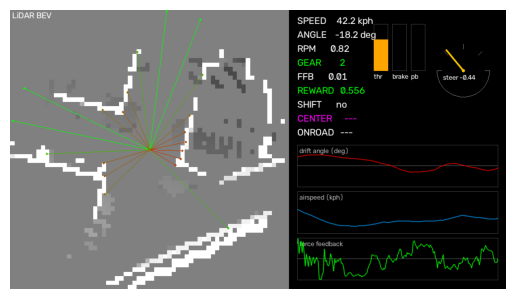

In [6]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
from beamng_tech_env import debug
from beamng_tech_env.core.constants import AIRSPEED_MAX_KPH
from data.dataset import load_dataset

ep = load_dataset("/home/admin/Projects/beamng-drift-project/drift-ai/data/human").episodes[2]
T = len(ep["reward"])
t = T // 2  # the middle of the episode

# the BEV the window shows: the (road-corrected) LiDAR BEV (the road_bev
# channel is dropped, as the live window renders only the BEV)
obs = {k: v for k, v in ep["obs"].items() if k != "road_bev"}
layout = debug.make_layout(960)
traces = debug.make_traces()

# seed the rolling traces with the samples before t, so the trace plots
# show the same sliding window the live window would (no per-frame reset)
def _hist(key, scale):
    arr = obs.get(key)
    return np.asarray(arr).reshape(-1) * scale if arr is not None else np.zeros(T)
for (label, *_), values in zip(
        debug._TRACE_SPECS,
        (_hist("drift_angle", 180.0),
         _hist("airspeed", AIRSPEED_MAX_KPH),
         _hist("ffb", 1.0))):
    traces[label].extend(values[:t])

# one frame through the live window's render path
payload = debug._payload_from({k: v[t] for k, v in obs.items()},
                              action=ep["action"][t],
                              reward=float(ep["reward"][t]), bev=None)
frame = debug._render_frame(cv2, payload, traces, layout)
plt.figure()
plt.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

## cupy (GPU) integration

The heavy per-step computation in the env is the observation processing: the LiDAR point cloud (the game writes it to shared memory) goes through road-surface removal and the BEV rasterisation, and the navigraph road network is rasterised into the road mask. All of this processing benefits from offloading to the GPU with cupy.

The integration is a single drop-in module, `core/array.py`: it exposes `np`, which is cupy when cupy is installed and plain numpy otherwise. The hot-path modules (`obs.py`, `roads.py`, `wrappers.py`) import `np` from there instead of from `numpy`, and the math is written in the shared numpy/cupy API, so the same code runs on either backend - there is no GPU-specific code path.

Data comes from the game as CPU numpy (the LiDAR shared memory, the State sensor), so the module also has two boundary functions: `to_gpu` moves data in (a no-op when cupy is not used) and `to_cpu` moves the finished observation back out, so the rest of the stack (gymnasium, the collector, the debug window) always sees plain numpy arrays.

Two details worth knowing:

- **Device choice.** By default cupy runs on the *last* CUDA device (`CUPY_DEVICE` selects a specific one): the game's renderer usually occupies the first GPU, so a second GPU avoids contending with it for GPU time.
- **Opt-in.** `USE_CUPY=0` forces the CPU backend even when cupy is installed - cupy is not imported at all and `to_gpu` / `to_cpu` become no-ops. The example env file disables CUPY usage by default.

With cupy, `VehicleRig.get_obs` also runs its two independent sub-paths (the point-cloud -> BEV path and the road BEV path) on separate non-blocking CUDA streams, so they overlap on the GPU; without cupy the streams are null and they run sequentially as before.

In [1]:
# which backend the env's hot path is running on (cupy when installed,
# numpy otherwise; USE_CUPY=0 forces the CPU backend)
from beamng_tech_env.core.array import USE_CUPY, CUPY_DEVICE, np
print("backend:", np.__name__, "| USE_CUPY:", USE_CUPY, "| device:", CUPY_DEVICE)

backend: cupy | USE_CUPY: True | device: 2


## Game transport

The env needs a transport between Python and the game to send the control (steering, throttle, brake, parking brake, gear) and receive the sensor stream (State, Electrics, Damage) every step. That path is the BeamNGpy tcom socket: the control is sent as a request with a blocking ack, the step and the sensor request go out as one batch, and the sensors are read back from the batch (re-polled once if the first read is stale). The LiDAR is read from shared memory - the direct, zero-hop path - and the force feedback comes over the socket.

The env also had a ROS2 transport (the in-game C++ bridge from the upstream [beamng-ros2-integration](https://github.com/BeamNG/beamng-ros2-integration), with a local `LD_PRELOAD` shim capping its 2 kHz scalar publish rate). I removed it: the socket + shared-memory path is just as fast, and it keeps the setup to a single game process with no ROS2 workspace.

In [1]:
# the env talks to the game over the BeamNGpy tcom socket (control + sensor
# stream) and reads the LiDAR from shared memory; there is no transport flag
import beamng_tech_env.core.rig as rig
print("transport: tcom socket (control + sensors) + shared memory (LiDAR)")

transport: tcom socket (control + sensors) + shared memory (LiDAR)


## Offline data

I added recording of transitions `(observation, action, reward, done)` to disk, which can be used to train offline (with the game closed) making training much faster. Along the way we also wire up BeamNG's *native* replay recording: in `--human` mode - every run collected has a matching `.rpl` replay a human can play back to verify a playthrough.

The `.rpl` can also be used with the `data.regenerate` module to re-create the stored transitions LiDAR - this was important to me because I have made many BEV iterations - in practice we have to reuse some of the data when this is done (FFB cannot be derived from a replay), so it cannot apply to any environment update to renew data, but it helped me throughout major updates to avoid throwing data away. The distance rays aren't stored, the source of truth thus becomes the code and the regenerated BEV, since these represent the input for these distance rays, which means we can change the angles of the rays.

There is also a recording mode which uses the BeamNG.tech native AI to generate data (option `--ai`).

### On-disk format

A dataset directory looks like this:

```
data/run1/
  episode_000000.npz  # one self-contained file per episode
  episode_000001.npz
  ...
```

Each `episode_*.npz` stores, as arrays of length `T` (the episode length):

- `obs_<key>` for every observation key (`obs_bev`, `obs_rpm`, `obs_imu_acc`,
  `obs_drift_angle`, `obs_airspeed`, ...)
- `action` `(T, 3)`, `reward` `(T,)`, `terminated` `(T,)`, `truncated` `(T,)`
- `info` (a list of the per-step info dicts)
- episode metadata: `ep_reward`, `ep_length`, `ep_terminated`, `ep_truncated`,
  `seed`, `replay` (the `.rpl` path, if replay recording was on), `timestamp`
- the dataset-level spaces, embedded so each file is self-contained:
  `space_obs`, `space_act` (pickled observation/action spaces) and `env_meta`

### Loading the data for offline training

`TrajectoryDataset` is a `torch.utils.data.Dataset` over the individual
transitions, and `to_replay_buffer` turns the whole dataset into a
Stable-Baselines3 replay buffer (a `DictReplayBuffer` for our Dict
observations). Both reconstruct the exact observation space from the
spaces embedded in each episode, so no information is lost in the round trip.

In [2]:
from data.dataset import load_dataset, to_replay_buffer

dataset = load_dataset("/home/admin/Projects/beamng-drift-project/drift-ai/data/human")
print(dataset.summary())

buffer = to_replay_buffer(dataset)  # SB3 DictReplayBuffer
batch = buffer.sample(256)
print(batch.actions.shape, batch.observations["bev"].shape)

159 episodes, 156659 transitions; episode reward mean=764.14 min=282.82 max=1561.87
torch.Size([256, 8]) torch.Size([256, 1, 64, 64])


## Better parallelization

A ZeroMQ game hosting option was created to help speed up training. 

It uses the request - response pattern where a request is a command, such as `step`, `reset`, and the expected response is made up of **[obs, reward, terminated, truncated, info]** for `step` or made up of **[obs, info]** for `reset`.

When training, it's possible to use multiple endpoints by passing a csv of `host:port` entries as the `--endpoints` argument (ex: `--endpoints 127.0.0.1:25252,192.168.1.2:25252`):

```bash
# host the game in a terminal
#on the local machine
./host_game.py 127.0.0.1 25252
#and on a machine you expect to access remotely (bind a visible IP).
./host_game.py 192.168.1.2 25252
# train using both game instances
"$VENV_PATH/bin/python" src/train/train.py online --algo td3 --action-noise 0.05 --timesteps 600000 --endpoints localhost:25252,192.168.1.2:25252
```

If you don't use `--endpoints`, one env instance is started automatically.

## Results

With the env in its current shape I trained **TD3** against the live game. The runs below are one continuous training chain (10.26 -> 10.27): the model was resumed across restarts, so the timesteps continue from one run directory to the next - the short runs in the list are interrupted attempts in between, and only the runs that reached an evaluation have eval points.

Behavior cloning initialized these weights, before online training which is shown in the graphs.

> Note: the graphs below were reproduced for your convenience, but normally when training you should launch tensorboard (`tensorboard --logdir="logs"`) and see them in a browser (http://localhost:6006/). The logs aren't committed, so the plots are the only record here.

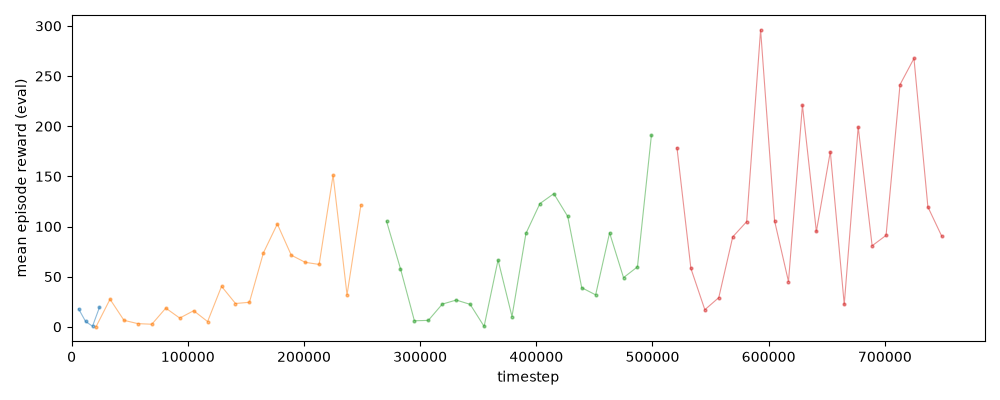

In [1]:
# average reward over timesteps, from the tensorboard event files of the
# TD3 runs below - the same data the `tensorboard` UI renders, plotted here
# so the notebook stays self-contained
import matplotlib.pyplot as plt
%matplotlib inline
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator

RUNS = [
    "/home/admin/Projects/beamng-drift-project/drift-ai/logs/TD3/2026.10.26-17.10/TD3_1",
    "/home/admin/Projects/beamng-drift-project/drift-ai/logs/TD3/2026.10.26-18.20/TD3_0",
    "/home/admin/Projects/beamng-drift-project/drift-ai/logs/TD3/2026.10.26-21.20/TD3_0",
    "/home/admin/Projects/beamng-drift-project/drift-ai/logs/TD3/2026.10.26-21.44/TD3_0",
    "/home/admin/Projects/beamng-drift-project/drift-ai/logs/TD3/2026.10.27-07.05/TD3_0",
    "/home/admin/Projects/beamng-drift-project/drift-ai/logs/TD3/2026.10.27-11.12/TD3_0",
    "/home/admin/Projects/beamng-drift-project/drift-ai/logs/TD3/2026.10.27-16.13/TD3_0",
    "/home/admin/Projects/beamng-drift-project/drift-ai/logs/TD3/2026.10.27-16.19/TD3_0",
    "/home/admin/Projects/beamng-drift-project/drift-ai/logs/TD3/2026.10.27-17.05/TD3_0",
    "/home/admin/Projects/beamng-drift-project/drift-ai/logs/TD3/2026.10.27-17.22/TD3_0",
    "/home/admin/Projects/beamng-drift-project/drift-ai/logs/TD3/2026.10.27-17.25/TD3_0",
    "/home/admin/Projects/beamng-drift-project/drift-ai/logs/TD3/2026.10.27-17.59/TD3_0",
    "/home/admin/Projects/beamng-drift-project/drift-ai/logs/TD3/2026.10.27-18.00/TD3_0",
]

fig, ax = plt.subplots(figsize=(10, 4))
for run_dir in RUNS:
    ea = EventAccumulator(run_dir)
    ea.Reload()
    if "eval/mean_reward" not in ea.Tags()["scalars"]:
        continue
    events = ea.Scalars("eval/mean_reward")
    ax.plot([e.step for e in events], [e.value for e in events],
            lw=0.8, alpha=0.5, marker="o", ms=2)
ax.set_xlim(0, None)
ax.set_xlabel("timestep")
ax.set_ylabel("mean episode reward (eval)")
plt.tight_layout()
plt.show()

The eval reward is noisy - each eval is a single episode, and the eval episodes are from random waypoints - but the level rises across the chain: single digits through the first ~25k timesteps, then peaks around 190-300 between 500k and 750k.

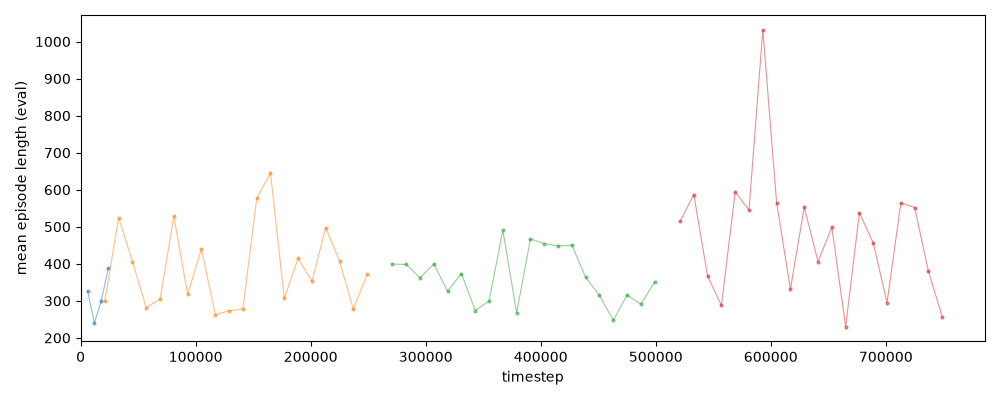

In [1]:
# same, for the mean episode length
import matplotlib.pyplot as plt
%matplotlib inline
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator

fig, ax = plt.subplots(figsize=(10, 4))
for run_dir in RUNS:
    ea = EventAccumulator(run_dir)
    ea.Reload()
    if "eval/mean_ep_length" not in ea.Tags()["scalars"]:
        continue
    events = ea.Scalars("eval/mean_ep_length")
    ax.plot([e.step for e in events], [e.value for e in events],
            lw=0.8, alpha=0.5, marker="o", ms=2)
ax.set_xlim(0, None)
ax.set_xlabel("timestep")
ax.set_ylabel("mean episode length (eval)")
plt.tight_layout()
plt.show()

The episode length tells the same story: from ~300 steps early on to peaks above 1000 steps in the last run. In this env a crash ends the episode, so a longer episode is the car surviving - and surviving while drifting is the whole point.

What I observed is that the TD3 model was sometimes stalling - this is because it's a deterministic policy, like explained above, and the way the LiDAR point cloud is simplified into beams (distance rays) plus the drift angle clipping to zero at low speed, can lead to a stable observation when the car isn't moving. With the policy then choosing not to move in that observation, it would result in getting the same observation next step, so when this happens the car sits still until the episode is truncated.

## Next steps

- Explore RNN's (recurrent neural networks). It is likely that the network having a history component will help it make better decisions while drifting - currently the simple policy always seems to just correct the ongoing drift, it seemingly isn't looking to extend it and if it happens, it's by accident.
- Train a CNN to predict beams, purely offline, and look into preloading it into the larger RNN architecture. I'd like the CNN to have more outputs besides beams which remain untrained - to be refined with online training, so I might also explore that variant.
- Possibly explore a code-only planning module (as opposed to a planning AI) and reward model to encourage the model to take turns by passing through gates linked with rewards. This will also need some observation space changes.